# Libraries

In [1]:
from ase.visualize import view
from ase.io import read
from ase.data import atomic_numbers, vdw_radii
from ase.build import surface, cut
from ase.geometry import get_duplicate_atoms
from ase.build import add_adsorbate
from ase import Atoms
import numpy as np
from typing import List, Tuple, Optional
from scipy.spatial import KDTree
from itertools import combinations
import nglview
from tqdm import tqdm
from scipy.spatial import cKDTree
from scipy.spatial import Delaunay

c:\Users\dangh\AppData\Local\Programs\Python\Python313\Lib\site-packages\nglview\__init__.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


# Support Functions

In [2]:
# Supporting Functions (unchanged)
def atomic_radii(structure_path):
    try:
        atoms = read(structure_path)
    except Exception as e:
        raise ValueError(f"Không thể đọc file : {e}")
    
    elements = set(atoms.get_chemical_symbols())
    radii_dict = {}
    for element in elements:
        atomic_number = atomic_numbers[element]
        radius = vdw_radii[atomic_number] if vdw_radii[atomic_number] != 0 else 1.0 
        radii_dict[element] = radius # in angstrom
        print(f"{element} radius: {radius}")
    
    return radii_dict

def molecule_surface_area(atoms, atom_radii, num_points=100000):
    coords_xy = np.array([atom.position[:2] for atom in atoms])
    radii = np.array([atom_radii[atom.symbol] for atom in atoms])
    min_x = np.min(coords_xy[:, 0] - radii)
    max_x = np.max(coords_xy[:, 0] + radii)
    min_y = np.min(coords_xy[:, 1] - radii)
    max_y = np.max(coords_xy[:, 1] + radii)
    box_area = (max_x - min_x) * (max_y - min_y)
    
    points_x = np.random.uniform(min_x, max_x, num_points)
    points_y = np.random.uniform(min_y, max_y, num_points)
    points = np.vstack((points_x, points_y)).T
    
    inside_count = 0
    for i in range(num_points):
        for j, center in enumerate(coords_xy):
            distance = np.sqrt(np.sum((points[i] - center) ** 2))
            if distance <= radii[j]:
                inside_count += 1
                break
    
    area_angstrom2 = (inside_count / num_points) * box_area
    area_nm2 = area_angstrom2 / 100
    print(f"Diện tích bề mặt phân tử (Top view): {area_angstrom2:.2f} Å², {area_nm2:.4f} nm²")
    return area_angstrom2, area_nm2

def compute_distances_vectorized(coords1, coords2):
    diff = coords1[:, np.newaxis] - coords2
    distances = np.sqrt(np.sum(diff**2, axis=2))
    return distances

def rotate_molecule_z_axis(adsorbate):
    rotated_adsorbate = adsorbate.copy()
    pivot = rotated_adsorbate[0].position.copy()
    theta = np.random.uniform(0, 360)
    theta_rad = np.radians(theta)
    
    rotation_matrix = np.array([
        [np.cos(theta_rad), -np.sin(theta_rad), 0],
        [np.sin(theta_rad), np.cos(theta_rad), 0],
        [0, 0, 1]
    ])
    
    rotated_adsorbate.positions -= pivot
    rotated_adsorbate.positions = np.dot(rotated_adsorbate.positions, rotation_matrix.T)
    rotated_adsorbate.positions += pivot
    
    return rotated_adsorbate

# Molecule Functions

In [3]:
# Precursor/Inhibitor Configuration Functions (unchanged)
def atomic_positions(structure_path):
    atoms = read(structure_path)
    radius = atomic_radii(structure_path)
    print("Atomic symbols:", atoms.get_chemical_symbols())
    print("Atomic positions (Å):")
    print(atoms.positions)
    for symbol, pos in zip(atoms.get_chemical_symbols(), atoms.positions):
        print(f"{symbol}: x={pos[0]:.4f}, y={pos[1]:.4f}, z={pos[2]:.4f}")
    return atoms, radius

def atomic_remove_indices(atoms, remove_indices=None):
    if remove_indices:
        keep_mask = [i not in remove_indices for i in range(len(atoms))]
        atoms = atoms[keep_mask]

    print(f"Sau khi loại bỏ nguyên tử thứ {remove_indices}, cấu trúc phân tử mới là:")
    for i, (s, p) in enumerate(zip(atoms.get_chemical_symbols(), atoms.positions)):
        print(f"{i}: {s} - x={p[0]:.8f}, y={p[1]:.8f}, z={p[2]:.8f}")

    return atoms

def rotate_adsorbate_flexible(adsorbate, ads_site, v1_type='two_atoms', indices=None):
    """Version với hướng mặc định 90 độ"""
    from scipy.spatial.transform import Rotation as R
    import numpy as np
    
    rotated_adsorbate = adsorbate.copy()
    pivot = rotated_adsorbate[0].position.copy()
    
    # Tính v1 như cũ
    if indices is None:
        indices = [1] if v1_type == 'two_atoms' else [1, 2]
    
    if v1_type == 'two_atoms':
        v1_end = rotated_adsorbate.positions[indices[0]]
        v1 = v1_end - pivot
    elif v1_type == 'centroid':
        other_atoms_positions = [rotated_adsorbate.positions[i] for i in indices]
        centroid = np.mean(other_atoms_positions, axis=0)
        v1 = centroid - pivot
    
    # Mặc định v2 là hướng 90 độ (thẳng đứng)
    v2 = np.array([0, 0, 1])  # Vector đơn vị hướng lên
    
    v1 /= np.linalg.norm(v1)
    # v2 đã là unit vector
    
    # Tính rotation
    cross = np.cross(v1, v2)
    dot = np.dot(v1, v2)
    
    if np.linalg.norm(cross) < 1e-8:
        if dot < 0:
            axis = np.array([1, 0, 0])
            angle = np.pi
        else:
            angle = 0.0
            axis = np.array([0, 0, 1])
    else:
        axis = cross / np.linalg.norm(cross)
        angle = np.arccos(np.clip(dot, -1.0, 1.0))
    
    rotation = R.from_rotvec(angle * axis)
    
    # Apply rotation
    rotated_adsorbate.translate(-pivot)
    rotated_adsorbate.positions = rotation.apply(rotated_adsorbate.positions)
    rotated_adsorbate.translate(ads_site)  # Move to ads_site position
    view(rotated_adsorbate)
    print(f"Applied vertical rotation - Angle: {np.degrees(angle):.1f}°")
    print(f"Adsorbate oriented vertically (90°) at position: {ads_site}")
    
    return rotated_adsorbate, angle, axis

# Slab Functions

In [4]:
'''
# Substrate Surface Configuration Functions (unchanged)
def generate_slab_from_cif(cif_path, miller_indices=(1, 0, 0), layers=4, vacuum=10.0, size=(1, 1, 1), repeat=(4, 4, 1)):
    structure = read(cif_path)
    slab = surface(structure, miller_indices, layers=layers, vacuum=vacuum)
    slab = slab.repeat(repeat)
    slab.pbc = [True, True, True]
    
    a1 = slab.cell[0]
    a2 = slab.cell[1]
    surface_area_angstrom2 = np.linalg.norm(np.cross(a1, a2))
    surface_area_nm2 = surface_area_angstrom2 / 100
    
    print(f"Slab created with Miller indices {miller_indices} and {len(slab)} atoms:")
    print(f"Cell: {slab.cell}")
    print(f"Surface area: {surface_area_nm2:.4f} nm²")
    
    return slab, surface_area_nm2

def generate_slab_from_cif(cif_path, miller_indices=(1, 0, 0), layers=4, vacuum=10.0, repeat=(4, 4, 1)):
    structure = read(cif_path)
    slab = surface(structure, miller_indices, layers=layers, vacuum=vacuum)

    # --- Chuyển sang orthogonal cell ---
    # surface() giữ nguyên cell gốc từ CIF, nên a1/a2 có thể không vuông góc (hình bình hành).
    # Cần tìm tổ hợp tuyến tính nguyên của a1, a2 để tạo 2 vector mới vuông góc nhau.
    #
    # Ý tưởng: giữ nguyên a1 làm trục x, sau đó tìm (p, q) nguyên sao cho:
    #   new_a2 = q*a2 - p*a1  vuông góc với a1
    #
    # Điều kiện vuông góc: dot(new_a2, a1) = 0
    #   => dot(q*a2 - p*a1, a1) = 0
    #   => q*dot(a2,a1) = p*|a1|²
    #   => p/q = dot(a2,a1) / |a1|²
    #
    # Vậy chỉ cần xấp xỉ ratio = dot(a2,a1)/|a1|² bằng phân số p/q (q <= max_denom).

    a1, a2 = slab.cell[0], slab.cell[1]
    ratio = np.dot(a2, a1) / np.dot(a1, a1)  # = p/q cần tìm

    # Tìm p/q xấp xỉ ratio tốt nhất với mẫu số q <= 20
    best_p, best_q, best_err = 0, 1, abs(ratio)
    for q in range(1, 21):
        p = round(q * ratio)
        err = abs(q * ratio - p)
        if err < best_err:
            best_p, best_q, best_err = p, q, err
        if err < 1e-6:
            break

    # Dùng ASE cut() để cắt lại supercell với basis mới:
    #   new_a1 = best_q * old_a1          (vẫn hướng cũ, nhân best_q lần)
    #   new_a2 = best_q * old_a2 - best_p * old_a1  (vuông góc với new_a1)
    #   new_a3 = giữ nguyên               (hướng vacuum, không đổi)
    slab = cut(
        slab,
        a=( best_q,        0, 0),   # new_a1 theo fractional coords
        b=(-best_p,  best_q, 0),    # new_a2 theo fractional coords
        c=None,                      # giữ nguyên a3
        extend=1.05,                 # lấy dư 5% tránh bỏ sót atom ở biên
        tolerance=0.5
    )

    # cut() đôi khi để lại cell hơi lệch do floating point,
    # nên force cell thành hình chữ nhật hoàn toàn (chỉ scale vị trí atom theo tỉ lệ).
    lx, ly, lz = [np.linalg.norm(slab.cell[i]) for i in range(3)]
    slab.set_cell([[lx,0,0],[0,ly,0],[0,0,lz]], scale_atoms=True)

    # Xóa duplicate atoms phát sinh do extend=1.05
    dup = get_duplicate_atoms(slab, cutoff=0.1)
    if len(dup):
        del slab[dup]

    # --- Repeat và PBC ---
    slab = slab.repeat(repeat)
    slab.pbc = [True, True, True]

    a1, a2 = slab.cell[0], slab.cell[1]
    surface_area_nm2 = np.linalg.norm(np.cross(a1, a2)) / 100

    print(f"Slab: Miller {miller_indices}, {len(slab)} atoms")
    print(f"Cell: {slab.cell}")
    print(f"Surface area: {surface_area_nm2:.4f} nm²")

    return slab, surface_area_nm2
'''
def generate_slab_from_cif(cif_path, miller_indices=(1, 0, 0), layers=4, vacuum=10.0, repeat=(4, 4, 1)):
    structure = read(cif_path)
    slab = surface(structure, miller_indices, layers=layers, vacuum=vacuum)

    # --- Chuyển sang orthogonal cell ---
    # surface() giữ nguyên cell gốc từ CIF, nên a1/a2 có thể không vuông góc (hình bình hành).
    # Cần tìm tổ hợp tuyến tính nguyên của a1, a2 để tạo 2 vector mới vuông góc nhau.
    #
    # Ý tưởng: giữ nguyên a1 làm trục x, sau đó tìm (p, q) nguyên sao cho:
    #   new_a2 = q*a2 - p*a1  vuông góc với a1
    #
    # Điều kiện vuông góc: dot(new_a2, a1) = 0
    #   => dot(q*a2 - p*a1, a1) = 0
    #   => q*dot(a2,a1) = p*|a1|²
    #   => p/q = dot(a2,a1) / |a1|²
    #
    # Vậy chỉ cần xấp xỉ ratio = dot(a2,a1)/|a1|² bằng phân số p/q (q <= max_denom).
    # Ghi nhớ top element từ surface() TRƯỚC khi cut() tránh đảo lộn bề mặt
    z_ref = slab.get_positions()[:, 2]
    cell_z_ref = slab.get_cell()[2, 2]
    frac_z_max = z_ref.max() / cell_z_ref  # nếu gần 1.0 → slab sát đỉnh → bị đảo lộn
    
    a1, a2 = slab.cell[0], slab.cell[1]
    ratio = np.dot(a2, a1) / np.dot(a1, a1)  # = p/q cần tìm

    # Tìm p/q xấp xỉ ratio tốt nhất với mẫu số q <= 20
    best_p, best_q, best_err = 0, 1, abs(ratio)
    for q in range(1, 21):
        p = round(q * ratio)
        err = abs(q * ratio - p)
        if err < best_err:
            best_p, best_q, best_err = p, q, err
        if err < 1e-6:
            break

    # Dùng ASE cut() để cắt lại supercell với basis mới:
    #   new_a1 = best_q * old_a1          (vẫn hướng cũ, nhân best_q lần)
    #   new_a2 = best_q * old_a2 - best_p * old_a1  (vuông góc với new_a1)
    #   new_a3 = giữ nguyên               (hướng vacuum, không đổi)
    slab = cut(
        slab,
        a=( best_q,        0, 0),   # new_a1 theo fractional coords
        b=(-best_p,  best_q, 0),    # new_a2 theo fractional coords
        c=None,                      # giữ nguyên a3
        extend=1.05,                 # lấy dư 5% tránh bỏ sót atom ở biên
        tolerance=0.5
    )

    # cut() đôi khi để lại cell hơi lệch do floating point,
    # nên force cell thành hình chữ nhật hoàn toàn (chỉ scale vị trí atom theo tỉ lệ).
    lx, ly, lz = [np.linalg.norm(slab.cell[i]) for i in range(3)]
    slab.set_cell([[lx,0,0],[0,ly,0],[0,0,lz]], scale_atoms=True)

    # Xóa duplicate atoms phát sinh do extend=1.05
    dup = get_duplicate_atoms(slab, cutoff=0.1)
    if len(dup):
        del slab[dup]

    # FIX: nếu slab nằm sát đỉnh cell (frac_z_max gần 1) → bị đảo lộn → flip
    z_pos = slab.get_positions()[:, 2]
    cell_z = slab.get_cell()[2, 2]
    if z_pos.min() > cell_z - z_pos.max():  # vacuum_bot > vacuum_top
        z_mid = (z_pos.max() + z_pos.min()) / 2
        slab.positions[:, 2] = 2 * z_mid - slab.positions[:, 2]

    slab.cell[2, 2] = slab.get_positions()[:, 2].max() + vacuum
    
    # --- Repeat và PBC ---
    slab = slab.repeat(repeat)
    slab.pbc = [True, True, True]

    a1, a2 = slab.cell[0], slab.cell[1]
    surface_area_nm2 = np.linalg.norm(np.cross(a1, a2)) / 100

    z_pos = slab.get_positions()[:, 2]
    syms = np.array(slab.get_chemical_symbols())
    print(f"Top layer: {set(syms[np.abs(z_pos - z_pos.max()) < 0.1])} @ z={z_pos.max():.3f}")
    print(f"Bot layer: {set(syms[np.abs(z_pos - z_pos.min()) < 0.1])} @ z={z_pos.min():.3f}")
    print(f"Slab: Miller {miller_indices}, {len(slab)} atoms")
    print(f"Cell: {slab.cell}")
    print(f"Surface area: {surface_area_nm2:.4f} nm²")

    return slab, surface_area_nm2

def gen_adsorption_sites(slab: Atoms, site_type: str = "ontop") -> List[np.ndarray]:
    """
    Generate adsorption sites on a slab surface.
    
    Parameters:
    - slab: ASE Atoms object of the slab
    - site_type: "ontop", "bridge", "hollow", or "all"
    
    Returns:
    - List of adsorption site coordinates [x, y, z]
    
    Example:
        sites = gen_adsorption_sites(slab, "bridge")
        print(f"Found {len(sites)} bridge sites")
    """
    # Find top layer atoms
    positions = slab.get_positions()
    z_coords = positions[:, 2]
    z_max = np.max(z_coords)
    tolerance = 1e-6
    
    top_layer_mask = np.abs(z_coords - z_max) < tolerance
    top_positions = positions[top_layer_mask]
    
    if len(top_positions) == 0:
        raise ValueError("No atoms found in the top layer")
    
    # Auto-detect characteristic distance (nearest neighbor)
    distance = _get_nn_distance(top_positions, slab.get_cell())
    height = z_max + 2.0  # 2 Å above surface
    
    # Calculate sites based on type
    if site_type == "ontop":
        sites = _calc_ontop_sites(top_positions, height)
    elif site_type == "bridge":
        sites = _calc_bridge_sites(top_positions, distance, height, slab.get_cell())
    elif site_type == "hollow":
        sites = _calc_hollow_sites(top_positions, distance, height, slab.get_cell())
    elif site_type == "all":
        sites = []
        sites.extend(_calc_ontop_sites(top_positions, height))
        sites.extend(_calc_bridge_sites(top_positions, distance, height, slab.get_cell()))
        sites.extend(_calc_hollow_sites(top_positions, distance, height, slab.get_cell()))
    else:
        raise ValueError(f"Unknown site_type: {site_type}")
    
    return sites

def _get_nn_distance(positions: np.ndarray, cell: np.ndarray) -> float:
    """Get nearest neighbor distance automatically."""
    min_dist = float('inf')
    cell_2d = cell[:2, :2] if cell is not None else None
    
    for i in range(len(positions)):
        for j in range(i+1, len(positions)):
            dist = _distance_pbc(positions[i][:2], positions[j][:2], cell_2d)
            if dist > 1e-6:  # Avoid zero distances
                min_dist = min(min_dist, dist)
    
    return min_dist if min_dist != float('inf') else 2.5

def _distance_pbc(pos1: np.ndarray, pos2: np.ndarray, cell: np.ndarray) -> float:
    """Calculate distance with periodic boundary conditions."""
    if cell is None:
        return np.linalg.norm(pos1 - pos2)
    
    diff = pos1 - pos2
    for i in range(2):
        if np.linalg.norm(cell[i]) > 0:
            length = np.linalg.norm(cell[i])
            diff[i] -= length * np.round(diff[i] / length)
    
    return np.linalg.norm(diff)

def _calc_ontop_sites(positions: np.ndarray, height: float) -> List[np.ndarray]:
    """Calculate ontop adsorption sites."""
    sites = []
    for pos in positions:
        site = pos.copy()
        site[2] = height
        sites.append(site)
    return sites

def _calc_bridge_sites(positions: np.ndarray, distance: float, height: float, cell: np.ndarray) -> List[np.ndarray]:
    sites = []
    tolerance = distance * 0.1
    
    lx = np.linalg.norm(cell[0])
    ly = np.linalg.norm(cell[1])

    # --- FIX PBC: tile ghost atoms sang 8 ô lân cận ---
    # Các cặp atom nằm ở 2 rìa đối diện sẽ không được nhận ra là nearest neighbor
    # nếu chỉ tính khoảng cách Cartesian thông thường → bỏ sót bridge site ở rìa.
    # Giải pháp: nhân bản atom, tìm cặp, chỉ giữ midpoint nằm trong ô gốc.
    extended_positions = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            shifted = positions.copy()
            shifted[:, 0] += dx * lx
            shifted[:, 1] += dy * ly
            extended_positions.append(shifted)
    extended_positions = np.vstack(extended_positions)

    for i in range(len(extended_positions)):
        for j in range(i + 1, len(extended_positions)):
            # Dùng khoảng cách Cartesian thẳng (không cần PBC nữa vì đã tile)
            dist = np.linalg.norm(
                extended_positions[i][:2] - extended_positions[j][:2]
            )

            if abs(dist - distance) < tolerance:
                midpoint = (extended_positions[i] + extended_positions[j]) / 2
                midpoint[2] = height

                # Chỉ giữ midpoint nằm trong ô gốc
                if not (0 <= midpoint[0] < lx and 0 <= midpoint[1] < ly):
                    continue

                is_duplicate = any(np.linalg.norm(midpoint - s) < 0.1 for s in sites)
                if not is_duplicate:
                    sites.append(midpoint)

    return sites

# Dùng code này đề phòng 1 số trường hợp lỗi khi tìm điểm hấp phụ hollow, dùng cho mọi trường hợp
def _calc_hollow_sites(positions, distance, height, cell):
    sites = []
    tolerance = distance * 0.3
    lx = np.linalg.norm(cell[0])
    ly = np.linalg.norm(cell[1])
    # Dùng range thực tế của atom, không dùng cell boundary
    x_min, x_max = positions[:, 0].min(), positions[:, 0].max()
    y_min, y_max = positions[:, 1].min(), positions[:, 1].max()
    extended_positions = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            shifted = positions.copy()
            shifted[:, 0] += dx * lx
            shifted[:, 1] += dy * ly
            extended_positions.append(shifted)
    extended_positions = np.vstack(extended_positions)
    try:
        tri = Delaunay(extended_positions[:, :2])
        seen = set()
        for triangle_indices in tri.simplices:
            triangle_pos = extended_positions[triangle_indices]
            side_lengths = [
                np.linalg.norm(triangle_pos[i][:2] - triangle_pos[(i+1)%3][:2])
                for i in range(3)
            ]
            if abs(np.mean(side_lengths) - distance) > tolerance:
                continue
            centroid = np.mean(triangle_pos, axis=0).copy()
            centroid[2] = height
            cx, cy = centroid[0], centroid[1]
            # Lọc: centroid phải nằm trong vùng atom thực tế (có offset)
            # Dùng half-cell padding để tránh bỏ sót điểm ở rìa
            pad = distance / 2
            if not (x_min - pad <= cx < x_max + pad and
                    y_min - pad <= cy < y_max + pad):
                continue
            # Wrap về vùng atom thực tế để kiểm tra duplicate
            cx_wrapped = (cx - x_min) % lx + x_min
            cy_wrapped = (cy - y_min) % ly + y_min
            key = (round(cx_wrapped / 0.05), round(cy_wrapped / 0.05))
            if key in seen:
                continue
            seen.add(key)
            centroid[0] = cx_wrapped
            centroid[1] = cy_wrapped
            sites.append(centroid)
    except Exception as e:
        print(f"Exception: {e}")
    return sites


# P, T, Sticking Prob & Ads Sites

In [5]:
'''
def calculate_N_hit(P, A, dt, m, T):
    T = T + 273.15 # Convert Celsius to Kelvin
    m = (m / 1000) / 6.022e23
    k = 1.38e-23
    flux = P / (2 * np.sqrt(2 * np.pi * m * k * T))
    N_hit = int(flux * A * dt)
    print(f"Calculated N_hit: {N_hit} molecules for P={P} Pa, A={A:.4f} m², dt={dt} s, m={m:.2e} kg, T={T} K")
    return N_hit
'''

def generate_and_adsorb_molecules_simplified(slab, adsorption_sites, N_hit, 
                                           existing_molecules, rotated_molecule, 
                                           radius, z_offset=2.0, z_range=(0.5, 5.0), 
                                           MAX_SITES=20, max_no_adsorption=50000, 
                                           molecule_type="precursor",
                                           sticking_probability=0.001,
                                           molecule_area_nm2=0.0, 
                                           surface_area_nm2=1.0,
                                           impingement_offset=0.0,
                                           coverage_offset=0.0,
                                           point_offset=0.0):
    
    new_adsorbed_molecules = []
    total_gas_generated = 0
    consecutive_no_adsorption = 0
    total_collision_attempts = 0 
    successful_sticking = 0
    rejected_by_sticking = 0  # New counter
    
    available_sites = adsorption_sites.copy()
    
    if len(available_sites) == 0:
        print(f"   No adsorption sites available for {molecule_type}")
        #return [], 0, available_sites
        return [], 0, available_sites, [], []
    
    cell = slab.get_cell()
    a1, a2 = cell[0], cell[1]
    slab_z_max = np.max(np.array(available_sites)[:, 2])
    
    pbar = tqdm(total=N_hit, desc=f"Processing {molecule_type}", ncols=80)
    coverage_log = []
    impingement_log = []
    point_log = []
    while total_gas_generated < N_hit and consecutive_no_adsorption < max_no_adsorption:
        
        if len(available_sites) == 0:
            print(f"   No more available sites for {molecule_type}")
            break
        
        # 1. Generate random position
        r1, r2 = np.random.rand(2)
        xy = r1 * a1[:2] + r2 * a2[:2]
        z = slab_z_max + z_offset + np.random.uniform(z_range[0], z_range[1])
        pos = np.array([xy[0], xy[1], z])
        total_gas_generated += 1
        
        # 2. APPLY STICKING PROBABILITY FIRST (right when molecule hits surface)
        total_collision_attempts += 1
        if np.random.random() >= sticking_probability:
            # Molecule bounces off - doesn't stick
            rejected_by_sticking += 1
            consecutive_no_adsorption += 1
            current_coverage = ((len(new_adsorbed_molecules) * molecule_area_nm2) / surface_area_nm2) + coverage_offset
            coverage_log.append(current_coverage)
            impingement_log.append((total_gas_generated + impingement_offset) / surface_area_nm2)
            point_log.append((len(new_adsorbed_molecules) / len(adsorption_sites)) + point_offset)
            pbar.update(1)
            continue
        
        # If we reach here, molecule wants to stick - now find a site
        successful_sticking += 1
        
        # 3. Try to find available surface site
        target_positions = np.array(available_sites)
        cu_tree = cKDTree(target_positions[:, :2])
        
        k = min(MAX_SITES, len(available_sites))
        _, indices = cu_tree.query(pos[:2], k=k)
        
        if isinstance(indices, (int, np.integer)):
            indices = [indices]
        
        adsorbed = False
        used_site_idx = None
        
        for site_idx in indices:
            if site_idx >= len(available_sites):
                continue
            
            target_site = available_sites[site_idx]
            
            # Use adsorbed structure for steric check
            test_molecule = rotated_molecule.copy()
            
            target_position = np.array(target_site).copy()
            target_position[2] = slab_z_max + z_offset
            
            offset = target_position - test_molecule.positions[0]
            test_molecule.translate(offset)
            
            # Apply random z-rotation
            test_molecule = rotate_molecule_z_axis(test_molecule)
            
            # Check steric hindrance
            no_overlap = True
            all_existing_molecules = existing_molecules + new_adsorbed_molecules
            
            if all_existing_molecules:
                symbols = []
                positions = []
                for existing_mol in all_existing_molecules:
                    symbols.extend(existing_mol.get_chemical_symbols())
                    positions.extend(existing_mol.get_positions())
                
                if positions:
                    all_existing_atoms = Atoms(symbols=symbols, positions=positions)
                    
                    distances = compute_distances_vectorized(test_molecule.positions, 
                                                           all_existing_atoms.positions)
                    
                    symbols_new = test_molecule.get_chemical_symbols()
                    symbols_existing = all_existing_atoms.get_chemical_symbols()
                    radii_new = np.array([radius[s] for s in symbols_new])
                    radii_existing = np.array([radius[s] for s in symbols_existing])
                    
                    radii_sums = radii_new[:, None] + radii_existing[None, :]
                    if not np.all(distances > radii_sums):
                        no_overlap = False
            
            # If found valid site, adsorb
            if no_overlap:
                new_adsorbed_molecules.append(test_molecule.copy())
                consecutive_no_adsorption = 0
                adsorbed = True
                target_site = available_sites[site_idx]
                #used_site_idx = site_idx
                break
        
        if adsorbed: #and used_site_idx is not None:
            #available_sites.pop(used_site_idx)
            available_sites = [s for s in available_sites if not np.allclose(s, target_site, atol=1e-6)]
            #current_coverage = ((len(new_adsorbed_molecules) * molecule_area_nm2) / surface_area_nm2) + coverage_offset
            #coverage_log.append(current_coverage)
            #impingement_log.append((total_gas_generated + impingement_offset) / surface_area_nm2)
            #point_log.append((total_gas_generated + point_offset) / surface_area_nm2)
        else:
            # Molecule wanted to stick but no space available
            consecutive_no_adsorption += 1
        current_coverage = ((len(new_adsorbed_molecules) * molecule_area_nm2) / surface_area_nm2) + coverage_offset
        coverage_log.append(current_coverage)
        impingement_log.append((total_gas_generated + impingement_offset) / surface_area_nm2)
        point_log.append((len(new_adsorbed_molecules) / len(adsorption_sites)) + point_offset)
        pbar.update(1)
        if total_gas_generated % 100 == 0:
            actual_efficiency = len(new_adsorbed_molecules) / total_gas_generated
            pbar.set_description(f"{molecule_type}: {len(new_adsorbed_molecules)} ads, "
                               f"{len(available_sites)} sites, eff={actual_efficiency:.4f}")
    
    pbar.close()
    
    if consecutive_no_adsorption >= max_no_adsorption:
        print(f"   Early termination: {consecutive_no_adsorption} consecutive failed attempts")
    
    actual_efficiency = len(new_adsorbed_molecules) / total_gas_generated if total_gas_generated > 0 else 0
    print(f"   {molecule_type.capitalize()}: {total_gas_generated} gas → {len(new_adsorbed_molecules)} adsorbed")
    print(f"   Rejected by sticking probability: {rejected_by_sticking}")
    print(f"   Wanted to stick but no space: {successful_sticking - len(new_adsorbed_molecules)}")
    print(f"   Actual adsorption efficiency: {actual_efficiency:.6f}")
    print(f"   Expected sticking probability: {sticking_probability:.6f}")
    print(f"   Remaining available sites: {len(available_sites)}")
    
    return new_adsorbed_molecules, total_gas_generated, available_sites, coverage_log, impingement_log, point_log


# Run

In [6]:
# Simplified ALD Simulation - Direct Surface Adsorption Only
N = 5
P = 1.6
precursor_pulse_time = 7
inhibitor_pulse_time = 120
inert_gas_purge_time = 20
MAX_SITES = 30
z_offset = 2.0
z_range = (2000, 5000.0)
max_no_adsorption = 2000

# Sticking probabilities (define these variables)
STICKING_PROB_PRECURSOR = 1
STICKING_PROB_INHIBITOR = 1

cycle_time = (inhibitor_pulse_time + precursor_pulse_time + 2 * inert_gas_purge_time)  # Removed co_reactant

number_gas_inhibitors = np.array([])
number_ads_inhibitors = np.array([])
number_gas_precursor = np.array([])
number_ads_precursor = np.array([])

# Generate slab and surface area
slab, surface_area_nm2 = generate_slab_from_cif(
    r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\CIF Files\SiO2_mp-8352_computed.cif",
    #r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\CIF Files\Cu.cif",
    miller_indices=(0, 0, 1), layers=1, vacuum=10, repeat=(12, 12, 1)
)
surface_area_m2 = surface_area_nm2 * 1e-18

# Load molecule structures
#atoms, radius = atomic_positions(r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\Structure File\qe cif file\TiCl4.sdf")
atoms, radius = atomic_positions(r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\Structure File\TMA.sdf")
atoms_filtered = atomic_remove_indices(atoms, remove_indices=[1,4,5,6])


#inhibitor_atoms, inhibitor_radius = atomic_positions(
#    r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\Structure File\DMADMS.sdf"
#)
#inhibitor_atoms_filtered = atomic_remove_indices(inhibitor_atoms, remove_indices=[1,2,5,6,7,8,15,16,17,18,19,20,21,22,23,24,25,26]) 


inhibitor_atoms, inhibitor_radius = atomic_positions(
    r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\Structure File\ET.sdf"
)
inhibitor_atoms_filtered = atomic_remove_indices(inhibitor_atoms, remove_indices=[8]) 

# Update radius dictionary
radius.update(inhibitor_radius)
radius['O'] = 1.52
#radius['Ru'] = 2.3
radius['Ti'] = 2.46  # Å
# Calculate molecular masses and N_hit values
#m_precursor = 72.09
#m_inhibitor = 62.14
#T = 150

#N_hit_precursor = calculate_N_hit(P, surface_area_m2, precursor_pulse_time, m_precursor, T)
N_hit_precursor = 10000
#N_hit_inhibitor = calculate_N_hit(P, surface_area_m2, inhibitor_pulse_time, m_inhibitor, T)
N_hit_inhibitor = 0 #10000

# Generate adsorption sites, site_type: "ontop", "bridge", "hollow"
INHIBITOR_SITE_TYPE = "ontop"
PRECURSOR_SITE_TYPE = "hollow" 
# Create working copy for site management across cycles
#available_sites = adsorption_sites.copy()
if INHIBITOR_SITE_TYPE == PRECURSOR_SITE_TYPE:
    # Dùng chung 1 list
    adsorption_sites_inhibitor = gen_adsorption_sites(slab, INHIBITOR_SITE_TYPE)
    adsorption_sites_precursor = adsorption_sites_inhibitor  # trỏ cùng list gốc
    available_sites_inhibitor = adsorption_sites_inhibitor.copy()
    available_sites_precursor = available_sites_inhibitor.copy()  # dùng chung
else:
    adsorption_sites_inhibitor = gen_adsorption_sites(slab, INHIBITOR_SITE_TYPE)
    adsorption_sites_precursor = gen_adsorption_sites(slab, PRECURSOR_SITE_TYPE)
    available_sites_inhibitor = adsorption_sites_inhibitor.copy()
    available_sites_precursor = adsorption_sites_precursor.copy()

# Create rotated molecule templates
selected_site = adsorption_sites_inhibitor[0]
rotated_adsorbate, _, _ = rotate_adsorbate_flexible(atoms_filtered, selected_site, v1_type='centroid', indices=[1, 2])
rotated_inhibitor, _, _ = rotate_adsorbate_flexible(inhibitor_atoms_filtered, selected_site, v1_type='centroid', indices=[0,4,3]) # indices=[1,2] for DMADMS, indices=[0,4,3] for ET

# Calculate molecular surface areas
_, precursor_area_nm2 = molecule_surface_area(rotated_adsorbate, atom_radii=radius)
_, inhibitor_area_nm2 = molecule_surface_area(rotated_inhibitor, atom_radii=radius)

# Initialize storage for adsorbed molecules
ads_inhibitor_molecules = []
ads_precursor_molecules = []

all_inh_coverage_log = []
all_inh_point_log = []
all_inh_impingement_log = []
all_pre_coverage_log = []
all_pre_point_log = []
all_pre_impingement_log = []

print(f'Starting ALD simulation with {N} cycles')
print(f'Surface area: {surface_area_nm2:.2f} nm²')
print(f'Initial adsorption sites: {len(available_sites_inhibitor)} for inhibitor, {len(available_sites_precursor)} for precursor')
print(f'N_hit precursor: {N_hit_precursor:.0f}')
print(f'N_hit inhibitor: {N_hit_inhibitor:.0f}')

# Main simulation loop
for cycle in range(1, N+1):
    print(f'\n{"="*50}')
    print(f'CYCLE {cycle}')
    print(f'{"="*50}')
    
    # Phase 1: Inhibitors (only in first cycle)
    #if cycle == 1:
    if True:
        print(f'\n1. INHIBITORS PHASE')
        new_inhibitors, gas_inhibitors_generated, available_sites_inhibitor, inh_coverage_log, inh_impingement_log, inh_point_log = generate_and_adsorb_molecules_simplified(
            #atoms=inhibitor_atoms,
            slab=slab,
            adsorption_sites=available_sites_inhibitor,  # Use available sites, not original
            N_hit=N_hit_inhibitor,
            existing_molecules=ads_inhibitor_molecules + ads_precursor_molecules, # use [] when no existing molecules in first cycle
            rotated_molecule=rotated_inhibitor,
            radius=radius,
            z_offset=z_offset,
            z_range=z_range,
            MAX_SITES=MAX_SITES,
            max_no_adsorption=max_no_adsorption,
            molecule_type="inhibitor",
            sticking_probability=STICKING_PROB_INHIBITOR,
            molecule_area_nm2=inhibitor_area_nm2,
            surface_area_nm2=surface_area_nm2,
            impingement_offset=sum(number_gas_inhibitors),
            coverage_offset=(sum(number_ads_inhibitors) * inhibitor_area_nm2) / surface_area_nm2,
            point_offset=sum(number_ads_inhibitors) / len(adsorption_sites_inhibitor)
        )
        
        ads_inhibitor_molecules.extend(new_inhibitors)
        # Đồng bộ lại nếu cùng site type
        if INHIBITOR_SITE_TYPE == PRECURSOR_SITE_TYPE:
            available_sites_precursor = available_sites_inhibitor
        all_inh_coverage_log.extend(inh_coverage_log)
        all_inh_point_log.extend(inh_point_log)
        all_inh_impingement_log.extend(inh_impingement_log)
        number_gas_inhibitors = np.append(number_gas_inhibitors, gas_inhibitors_generated)
        number_ads_inhibitors = np.append(number_ads_inhibitors, len(new_inhibitors))
    #else:
        # No inhibitors in subsequent cycles
        #number_gas_inhibitors = np.append(number_gas_inhibitors, 0)
        #number_ads_inhibitors = np.append(number_ads_inhibitors, 0)
        #all_inh_coverage_log.extend([])   # thêm dòng này
        #all_inh_impingement_log.extend([]) # thêm dòng này
        #all_inh_point_log.extend([]) # thêm dòng này
    
    # Phase 2: Precursors (all cycles)
    print(f'\n2. PRECURSORS PHASE')
    
    # All existing molecules (inhibitors + precursors from previous cycles)
    all_existing_molecules = ads_inhibitor_molecules + ads_precursor_molecules
    
    new_precursors, gas_precursors_generated, available_sites_precursor, pre_coverage_log, pre_impingement_log, pre_point_log = generate_and_adsorb_molecules_simplified(
        #atoms=atoms,
        slab=slab,
        adsorption_sites=available_sites_precursor,  # Use updated available sites
        N_hit=N_hit_precursor,
        existing_molecules=all_existing_molecules,
        rotated_molecule=rotated_adsorbate,
        radius=radius,
        z_offset=z_offset,
        z_range=z_range,
        MAX_SITES=MAX_SITES,
        max_no_adsorption=max_no_adsorption,
        molecule_type="precursor",
        sticking_probability=STICKING_PROB_PRECURSOR,
        molecule_area_nm2=precursor_area_nm2,
        surface_area_nm2=surface_area_nm2,
        impingement_offset=sum(number_gas_precursor),
        coverage_offset=(sum(number_ads_precursor) * precursor_area_nm2) / surface_area_nm2,
        point_offset=sum(number_ads_precursor) / len(adsorption_sites_precursor)
    )
    
    # Add newly adsorbed precursors to the collection
    ads_precursor_molecules.extend(new_precursors)
    if INHIBITOR_SITE_TYPE == PRECURSOR_SITE_TYPE:
        available_sites_inhibitor = available_sites_precursor
    all_pre_coverage_log.extend(pre_coverage_log)
    all_pre_impingement_log.extend(pre_impingement_log)
    all_pre_point_log.extend(pre_point_log)
    number_gas_precursor = np.append(number_gas_precursor, gas_precursors_generated)
    number_ads_precursor = np.append(number_ads_precursor, len(new_precursors))
    
    # Cycle summary
    print(f'\n--- CYCLE {cycle} SUMMARY ---')
    if cycle == 1:
        print(f'Inhibitors adsorbed: {len(ads_inhibitor_molecules)}')
    print(f'Precursors adsorbed this cycle: {len(new_precursors)}')
    print(f'Total precursors: {len(ads_precursor_molecules)}')
    print(f'Total molecules in system: {len(ads_inhibitor_molecules) + len(ads_precursor_molecules)}')

# Calculate coverage statistics
total_inhibitors = len(ads_inhibitor_molecules)
total_precursors = len(ads_precursor_molecules)
total_molecules = total_inhibitors + total_precursors

area_coverage_inhibitor = (total_inhibitors * inhibitor_area_nm2) / surface_area_nm2 if surface_area_nm2 > 0 else 0
area_coverage_precursor = (total_precursors * precursor_area_nm2) / surface_area_nm2 if surface_area_nm2 > 0 else 0
total_coverage = area_coverage_inhibitor + area_coverage_precursor

# Final Summary
print(f'\n{"="*60}')
print(f'SIMULATION COMPLETED - FINAL SUMMARY')
print(f'{"="*60}')
print(f'Total Cycles: {N}')
print(f'Total Inhibitors Adsorbed: {total_inhibitors}')
print(f'Total Precursors Adsorbed: {total_precursors}')
print(f'Total Molecules in System: {total_molecules}')
print(f'\nArea Coverage:')
print(f'  Inhibitor: {area_coverage_inhibitor:.4f} ({total_inhibitors} molecules)')
print(f'  Precursor: {area_coverage_precursor:.4f} ({total_precursors} molecules)')
print(f'  Total: {total_coverage:.4f}')

# Collision Efficiency Analysis
print(f'\n{"="*60}')
print(f'COLLISION EFFICIENCY ANALYSIS')
print(f'{"="*60}')
total_gas = np.sum(number_gas_precursor) + np.sum(number_gas_inhibitors)
total_ads = np.sum(number_ads_precursor) + np.sum(number_ads_inhibitors)
overall_efficiency = total_ads / total_gas if total_gas > 0 else 0

print(f'Overall adsorption efficiency: {overall_efficiency:.6f} ({total_ads}/{total_gas})')
print(f'Expected efficiency (precursor): {STICKING_PROB_PRECURSOR:.6f}')
print(f'Expected efficiency (inhibitor): {STICKING_PROB_INHIBITOR:.6f}')

# Individual molecule type efficiencies
precursor_gas = np.sum(number_gas_precursor)
precursor_ads = np.sum(number_ads_precursor)
precursor_efficiency = precursor_ads / precursor_gas if precursor_gas > 0 else 0
print(f'Precursor efficiency: {precursor_efficiency:.6f} ({precursor_ads}/{precursor_gas})')

if np.sum(number_gas_inhibitors) > 0:
    inhibitor_gas = np.sum(number_gas_inhibitors)
    inhibitor_ads = np.sum(number_ads_inhibitors)
    inhibitor_efficiency = inhibitor_ads / inhibitor_gas if inhibitor_gas > 0 else 0
    print(f'Inhibitor efficiency: {inhibitor_efficiency:.6f} ({inhibitor_ads}/{inhibitor_gas})')

# Detailed cycle-by-cycle statistics
print(f'\n📈 DETAILED CYCLE STATISTICS:')
print(f'Sticking Probability Settings:')
print(f'  - Precursor: {STICKING_PROB_PRECURSOR:.6f}')
print(f'  - Inhibitor: {STICKING_PROB_INHIBITOR:.6f}')
print()

for i in range(len(number_gas_inhibitors)):
    cycle_num = i + 1
    print(f'Cycle {cycle_num}:')
    print(f'  - Gas inhibitors: {int(number_gas_inhibitors[i])}')
    print(f'  - Adsorbed inhibitors: {int(number_ads_inhibitors[i])}')
    print(f'  - Gas precursors: {int(number_gas_precursor[i])}')
    print(f'  - Adsorbed precursors: {int(number_ads_precursor[i])}')
    
    if number_gas_inhibitors[i] > 0:
        inh_eff = number_ads_inhibitors[i] / number_gas_inhibitors[i]
        print(f'  - Inhibitor efficiency: {inh_eff:.6f}')
    if number_gas_precursor[i] > 0:
        pre_eff = number_ads_precursor[i] / number_gas_precursor[i]
        print(f'  - Precursor efficiency: {pre_eff:.6f}')
    print()

print(f'{"="*60}')

# Create final structure for visualization
all_adsorbed_molecules = ads_inhibitor_molecules + ads_precursor_molecules
print(f'Total molecules for visualization: {len(all_adsorbed_molecules)}')

if len(all_adsorbed_molecules) > 0:
    all_symbols = []
    all_positions = []
    
    # Add slab atoms
    all_symbols.extend(slab.get_chemical_symbols())
    all_positions.extend(slab.get_positions())
    
    # Add all adsorbed molecules
    for molecule in all_adsorbed_molecules:
        all_symbols.extend(molecule.get_chemical_symbols())
        all_positions.extend(molecule.get_positions())
    
    final_structure = Atoms(symbols=all_symbols, positions=all_positions)
    print('✓ Final structure created successfully for visualization')
else:
    print('⚠️ No molecules were adsorbed. Only slab will be available for visualization.')
    final_structure = slab.copy()

# Visualization
print('\n📊 VISUALIZATION')
print('Displaying final structure with nglview...')
view(final_structure, viewer='ngl')

print('\n🎉 SIMULATION COMPLETED SUCCESSFULLY!')
print(f'Final structure variable: final_structure')
print(f'Total atoms in final structure: {len(final_structure)}')
print(f'Available variables:')
print(f'  - final_structure: Complete structure (slab + molecules)')
print(f'  - ads_inhibitor_molecules: List of adsorbed inhibitor molecules')
print(f'  - ads_precursor_molecules: List of adsorbed precursor molecules')
print(f'  - slab: Original surface slab')
print(f'  - adsorption_sites_inhibitor / adsorption_sites_precursor: Original surface adsorption sites')
if INHIBITOR_SITE_TYPE == PRECURSOR_SITE_TYPE:
    print(f'  - available_sites: {len(available_sites_precursor)} sites remaining')
else:
    print(f'  - available_sites_inhibitor: {len(available_sites_inhibitor)} sites remaining')
    print(f'  - available_sites_precursor: {len(available_sites_precursor)} sites remaining')

Top layer: {np.str_('O')} @ z=11.615
Bot layer: {np.str_('Si')} @ z=10.000
Slab: Miller (0, 0, 1), 1152 atoms
Cell: Cell([126.61512864, 109.65191790567462, 21.61532530669194])
Surface area: 138.8359 nm²
Al radius: 1.84
H radius: 1.2
C radius: 1.7
Atomic symbols: ['Al', 'C', 'C', 'C', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H']
Atomic positions (Å):
[[ 1.0684  0.2044 -0.5349]
 [ 0.1205 -1.5451 -0.4216]
 [ 0.1221  1.5919  0.5433]
 [ 2.9581  0.0162  0.0727]
 [-0.3736 -1.6472  0.5646]
 [-0.6471 -1.5973 -1.2229]
 [ 0.8492 -2.3699 -0.5506]
 [ 0.5335  1.6163  1.5741]
 [ 0.264   2.5828  0.0645]
 [-0.9616  1.3566  0.5851]
 [ 3.309  -1.0185 -0.1205]
 [ 3.5924  0.73   -0.4915]
 [ 3.0309  0.2357  1.1591]]
Al: x=1.0684, y=0.2044, z=-0.5349
C: x=0.1205, y=-1.5451, z=-0.4216
C: x=0.1221, y=1.5919, z=0.5433
C: x=2.9581, y=0.0162, z=0.0727
H: x=-0.3736, y=-1.6472, z=0.5646
H: x=-0.6471, y=-1.5973, z=-1.2229
H: x=0.8492, y=-2.3699, z=-0.5506
H: x=0.5335, y=1.6163, z=1.5741
H: x=0.2640, y=2.5828, z=0.06

Processing inhibitor: 0it [00:00, ?it/s]


   Inhibitor: 0 gas → 0 adsorbed
   Rejected by sticking probability: 0
   Wanted to stick but no space: 0
   Actual adsorption efficiency: 0.000000
   Expected sticking probability: 1.000000
   Remaining available sites: 576

2. PRECURSORS PHASE


precursor: 290 ads, 862 sites, eff=0.0630:  46%|▍| 4620/10000 [11:51<13:48,  6.4


   Early termination: 2000 consecutive failed attempts
   Precursor: 4620 gas → 290 adsorbed
   Rejected by sticking probability: 0
   Wanted to stick but no space: 4330
   Actual adsorption efficiency: 0.062771
   Expected sticking probability: 1.000000
   Remaining available sites: 862

--- CYCLE 1 SUMMARY ---
Inhibitors adsorbed: 0
Precursors adsorbed this cycle: 290
Total precursors: 290
Total molecules in system: 290

CYCLE 2

1. INHIBITORS PHASE


...

   Early termination: 2000 consecutive failed attempts
   Precursor: 2000 gas → 0 adsorbed
   Rejected by sticking probability: 0
   Wanted to stick but no space: 2000
   Actual adsorption efficiency: 0.000000
   Expected sticking probability: 1.000000
   Remaining available sites: 862

--- CYCLE 4 SUMMARY ---
Precursors adsorbed this cycle: 0
Total precursors: 290
Total molecules in system: 290

CYCLE 5

1. INHIBITORS PHASE


Processing inhibitor: 0it [00:00, ?it/s]


   Inhibitor: 0 gas → 0 adsorbed
   Rejected by sticking probability: 0
   Wanted to stick but no space: 0
   Actual adsorption efficiency: 0.000000
   Expected sticking probability: 1.000000
   Remaining available sites: 576

2. PRECURSORS PHASE


precursor: 1 ads, 861 sites, eff=0.0004:  24%|▏| 2440/10000 [06:02<18:44,  6.73i


   Early termination: 2000 consecutive failed attempts
   Precursor: 2440 gas → 1 adsorbed
   Rejected by sticking probability: 0
   Wanted to stick but no space: 2439
   Actual adsorption efficiency: 0.000410
   Expected sticking probability: 1.000000
   Remaining available sites: 861

--- CYCLE 5 SUMMARY ---
Precursors adsorbed this cycle: 1
Total precursors: 291
Total molecules in system: 291

SIMULATION COMPLETED - FINAL SUMMARY
Total Cycles: 5
Total Inhibitors Adsorbed: 0
Total Precursors Adsorbed: 291
Total Molecules in System: 291

Area Coverage:
  Inhibitor: 0.0000 (0 molecules)
  Precursor: 0.5113 (291 molecules)
  Total: 0.5113

COLLISION EFFICIENCY ANALYSIS
Overall adsorption efficiency: 0.022282 (291.0/13060.0)
Expected efficiency (precursor): 1.000000
Expected efficiency (inhibitor): 1.000000
Precursor efficiency: 0.022282 (291.0/13060.0)

📈 DETAILED CYCLE STATISTICS:
Sticking Probability Settings:
  - Precursor: 1.000000
  - Inhibitor: 1.000000

Cycle 1:
  - Gas inhibitor

In [7]:
view(final_structure, viewer='ngl')

In [8]:
# Coverage Analysis
print(f'{"="*60}')
print(f'COVERAGE ANALYSIS')
print(f'{"="*60}')

# Calculate coverage (#/nm²)
inhibitor_coverage = total_inhibitors / surface_area_nm2 if surface_area_nm2 > 0 else 0
precursor_coverage = total_precursors / surface_area_nm2 if surface_area_nm2 > 0 else 0
total_coverage_molecules = (total_inhibitors + total_precursors) / surface_area_nm2 if surface_area_nm2 > 0 else 0

print(f'Surface area: {surface_area_nm2:.4f} nm²')
print(f'')
print(f'Coverage of Molecules (#/nm²):')
print(f'  - Inhibitor coverage: {inhibitor_coverage:.4f} molecules/nm²')
print(f'    ({total_inhibitors} molecules / {surface_area_nm2:.4f} nm²)')
print(f'  - Precursor coverage: {precursor_coverage:.4f} molecules/nm²')
print(f'    ({total_precursors} molecules / {surface_area_nm2:.4f} nm²)')
print(f'  - Total coverage: {total_coverage_molecules:.4f} molecules/nm²')
print(f'    ({total_molecules} molecules / {surface_area_nm2:.4f} nm²)')

# Additional analysis: coverage vs theoretical maximum
if INHIBITOR_SITE_TYPE == PRECURSOR_SITE_TYPE:
    total_sites = len(adsorption_sites_inhibitor)
    sites_per_nm2 = total_sites / surface_area_nm2 if surface_area_nm2 > 0 else 0
    site_occupancy = total_molecules / total_sites if total_sites > 0 else 0
    coverage_percentage = (total_coverage_molecules / sites_per_nm2) * 100 if sites_per_nm2 > 0 else 0

    print(f'')
    print(f'Site Analysis:')
    print(f'  - Total adsorption sites: {total_sites}')
    print(f'  - Maximum theoretical coverage: {sites_per_nm2:.4f} molecules/nm²')
    print(f'  - Actual coverage percentage: {coverage_percentage:.2f}%')
    print(f'  - Site occupancy: {site_occupancy:.4f} ({site_occupancy*100:.2f}%)')
    print(f'  - Available sites remaining: {len(available_sites_precursor)}')
else:
    inhibitor_occupancy = total_inhibitors / len(adsorption_sites_inhibitor) if len(adsorption_sites_inhibitor) > 0 else 0
    precursor_occupancy = total_precursors / len(adsorption_sites_precursor) if len(adsorption_sites_precursor) > 0 else 0

    print(f'')
    print(f'Site Analysis:')
    print(f'  - Inhibitor sites: {len(adsorption_sites_inhibitor)}, Precursor sites: {len(adsorption_sites_precursor)}')
    print(f'  - Inhibitor site occupancy: {inhibitor_occupancy:.4f} ({inhibitor_occupancy*100:.2f}%)')
    print(f'  - Precursor site occupancy: {precursor_occupancy:.4f} ({precursor_occupancy*100:.2f}%)')
    print(f'  - Available sites remaining: {len(available_sites_inhibitor)} inhibitor, {len(available_sites_precursor)} precursor')
print(f'{"="*60}')

# Point Coverage Analysis
print(f'\n{"="*60}')
print(f'POINT COVERAGE ANALYSIS')
print(f'{"="*60}')

if INHIBITOR_SITE_TYPE == PRECURSOR_SITE_TYPE:
    total_sites = len(adsorption_sites_inhibitor)
else:
    total_sites = len(adsorption_sites_inhibitor) + len(adsorption_sites_precursor)

# Inhibitor point coverage
inhibitor_point_coverage = (total_inhibitors / len(adsorption_sites_inhibitor)) * 100 if len(adsorption_sites_inhibitor) > 0 else 0
print(f'Inhibitor point coverage: {inhibitor_point_coverage:.2f}%')
print(f'  ({total_inhibitors} molecules / {len(adsorption_sites_inhibitor)} sites)')

# Precursor point coverage
precursor_point_coverage = (total_precursors / len(adsorption_sites_precursor)) * 100 if len(adsorption_sites_precursor) > 0 else 0
print(f'Precursor point coverage: {precursor_point_coverage:.2f}%')
print(f'  ({total_precursors} molecules / {len(adsorption_sites_precursor)} sites)')

# Total point coverage
total_point_coverage = (total_molecules / total_sites) * 100 if total_sites > 0 else 0
print(f'\nTotal point coverage: {total_point_coverage:.2f}%')
print(f'  ({total_molecules} total molecules / {total_sites} sites)')

# Comparison with area coverage
print(f'\nComparison:')
print(f'  - Point coverage: {total_point_coverage:.2f}% (based on site occupancy)')
print(f'  - Area coverage: {total_coverage:.4f} (based on molecular area)')

print(f'{"="*60}')

# Physical Impingement Analysis
print(f'\n{"="*60}')
print(f'PHYSICAL IMPINGEMENT ANALYSIS')
print(f'{"="*60}')

# Calculate physical impingement for each molecule type
precursor_impingement = precursor_gas / surface_area_nm2 if surface_area_nm2 > 0 else 0
print(f'Precursor physical impingement: {precursor_impingement:.2f} #/nm²')
print(f'  ({precursor_gas} molecules / {surface_area_nm2:.4f} nm²)')

if np.sum(number_gas_inhibitors) > 0:
    inhibitor_impingement = inhibitor_gas / surface_area_nm2 if surface_area_nm2 > 0 else 0
    print(f'Inhibitor physical impingement: {inhibitor_impingement:.2f} #/nm²')
    print(f'  ({inhibitor_gas} molecules / {surface_area_nm2:.4f} nm²)')

# Total physical impingement
total_impingement = total_gas / surface_area_nm2 if surface_area_nm2 > 0 else 0
print(f'\nTotal physical impingement: {total_impingement:.2f} #/nm²')
print(f'  ({total_gas} total molecules / {surface_area_nm2:.4f} nm²)')

print(f'{"="*60}')

COVERAGE ANALYSIS
Surface area: 138.8359 nm²

Coverage of Molecules (#/nm²):
  - Inhibitor coverage: 0.0000 molecules/nm²
    (0 molecules / 138.8359 nm²)
  - Precursor coverage: 2.0960 molecules/nm²
    (291 molecules / 138.8359 nm²)
  - Total coverage: 2.0960 molecules/nm²
    (291 molecules / 138.8359 nm²)

Site Analysis:
  - Inhibitor sites: 576, Precursor sites: 1152
  - Inhibitor site occupancy: 0.0000 (0.00%)
  - Precursor site occupancy: 0.2526 (25.26%)
  - Available sites remaining: 576 inhibitor, 861 precursor

POINT COVERAGE ANALYSIS
Inhibitor point coverage: 0.00%
  (0 molecules / 576 sites)
Precursor point coverage: 25.26%
  (291 molecules / 1152 sites)

Total point coverage: 16.84%
  (291 total molecules / 1728 sites)

Comparison:
  - Point coverage: 16.84% (based on site occupancy)
  - Area coverage: 0.5113 (based on molecular area)

PHYSICAL IMPINGEMENT ANALYSIS
Precursor physical impingement: 94.07 #/nm²
  (13060.0 molecules / 138.8359 nm²)

Total physical impingement:

In [9]:
# Physical Impingement Analysis
print(f'\n{"="*60}')
print(f'PHYSICAL IMPINGEMENT ANALYSIS')
print(f'{"="*60}')

# Per cycle breakdown
print(f'\nPer-cycle physical impingement:')
for i in range(len(number_gas_precursor)):
    cycle_num = i + 1
    cycle_gas = number_gas_precursor[i] + number_gas_inhibitors[i]
    cycle_impingement = cycle_gas / surface_area_nm2 if surface_area_nm2 > 0 else 0
    
    print(f'Cycle {cycle_num}:')
    if number_gas_inhibitors[i] > 0:
        inh_imp = number_gas_inhibitors[i] / surface_area_nm2
        print(f'  - Inhibitor: {inh_imp:.2f} #/nm² ({int(number_gas_inhibitors[i])} molecules)')
    pre_imp = number_gas_precursor[i] / surface_area_nm2
    print(f'  - Precursor: {pre_imp:.2f} #/nm² ({int(number_gas_precursor[i])} molecules)')
    print(f'  - Cycle total: {cycle_impingement:.2f} #/nm²')

# Cumulative totals
precursor_impingement = np.sum(number_gas_precursor) / surface_area_nm2
inhibitor_impingement = np.sum(number_gas_inhibitors) / surface_area_nm2
total_impingement = (np.sum(number_gas_precursor) + np.sum(number_gas_inhibitors)) / surface_area_nm2

print(f'\nCumulative physical impingement:')
if np.sum(number_gas_inhibitors) > 0:
    print(f'  - Inhibitor: {inhibitor_impingement:.2f} #/nm²')
print(f'  - Precursor: {precursor_impingement:.2f} #/nm²')
print(f'  - Total: {total_impingement:.2f} #/nm²')

print(f'\nSurface area: {surface_area_nm2:.4f} nm²')
print(f'Total gas molecules generated: {int(np.sum(number_gas_precursor) + np.sum(number_gas_inhibitors))}')

print(f'{"="*60}')


PHYSICAL IMPINGEMENT ANALYSIS

Per-cycle physical impingement:
Cycle 1:
  - Precursor: 33.28 #/nm² (4620 molecules)
  - Cycle total: 33.28 #/nm²
Cycle 2:
  - Precursor: 14.41 #/nm² (2000 molecules)
  - Cycle total: 14.41 #/nm²
Cycle 3:
  - Precursor: 14.41 #/nm² (2000 molecules)
  - Cycle total: 14.41 #/nm²
Cycle 4:
  - Precursor: 14.41 #/nm² (2000 molecules)
  - Cycle total: 14.41 #/nm²
Cycle 5:
  - Precursor: 17.57 #/nm² (2440 molecules)
  - Cycle total: 17.57 #/nm²

Cumulative physical impingement:
  - Precursor: 94.07 #/nm²
  - Total: 94.07 #/nm²

Surface area: 138.8359 nm²
Total gas molecules generated: 13060


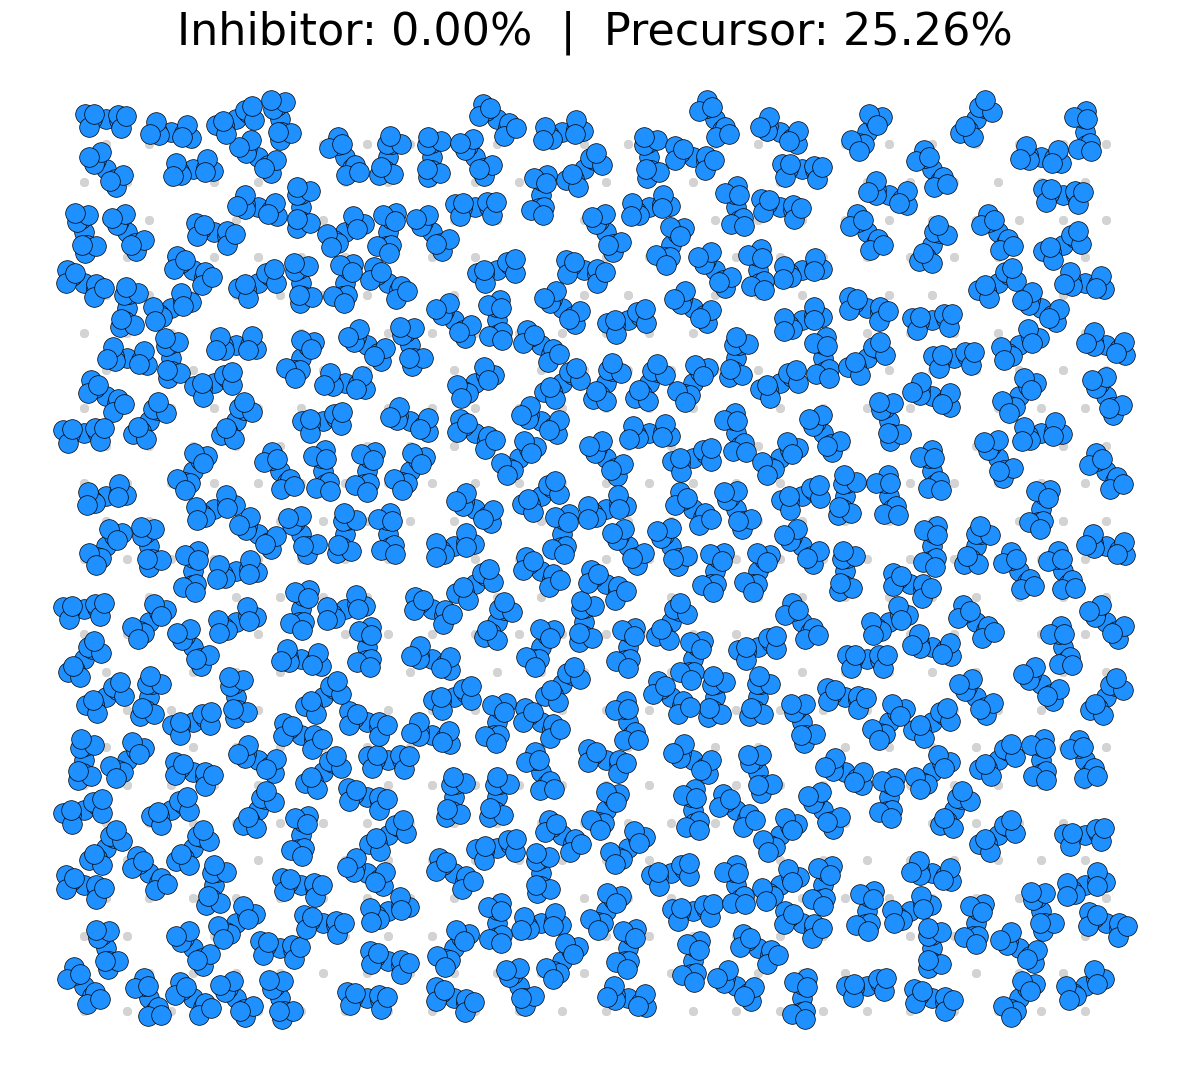

In [10]:
from ase.visualize.plot import plot_atoms
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

# Surface atoms
slab_pos = slab.get_positions()
ax.scatter(slab_pos[:, 0], slab_pos[:, 1], s=30, c='lightgray', zorder=1, label='Surface')

# Inhibitor
for mol in ads_inhibitor_molecules:
    pos = mol.get_positions()
    ax.scatter(pos[:, 0], pos[:, 1], s=200, c='orangered',
               edgecolors='black', linewidths=0.5, zorder=3)

# Precursor
for mol in ads_precursor_molecules:
    pos = mol.get_positions()
    ax.scatter(pos[:, 0], pos[:, 1], s=200, c='dodgerblue',
               edgecolors='black', linewidths=0.5, zorder=3)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='lightgray',  label='Surface'),
    Patch(facecolor='orangered',  label=f'Inhibitor ({total_inhibitors})'),
    Patch(facecolor='dodgerblue', label=f'Precursor ({total_precursors})'),
]
#ax.legend(handles=legend_elements, fontsize=13, loc='upper right')
ax.set_aspect('equal')
ax.set_title(f'Inhibitor: {inhibitor_point_coverage:.2f}%  |  Precursor: {precursor_point_coverage:.2f}%', fontsize=32)
ax.axis('off')
plt.tight_layout()
plt.savefig('TiN_SiO2_topview.png', dpi=300, bbox_inches='tight')
plt.show()


In [11]:
# Số lượng phân tử trên mỗi nm²
print('Inhibitor coverage (#/nm²):')
max_coverage_theory = 1 / inhibitor_area_nm2  # #/nm²
print(f"Lý thuyết tối đa: {max_coverage_theory:.3f} #/nm²")
sim_coverage = number_ads_inhibitors.sum() / surface_area_nm2
print(f"Giá trị mô phỏng : {sim_coverage:.3f} #/nm²")
print(f'='*60)
print(f'Precursor coverage (#/nm²):')
max_coverage_theory = 1 / precursor_area_nm2  # #/nm²
print(f"Lý thuyết tối đa: {max_coverage_theory:.3f} #/nm²")
sim_coverage = number_ads_precursor.sum() / surface_area_nm2
print(f"Giá trị mô phỏng : {sim_coverage:.3f} #/nm²")

Inhibitor coverage (#/nm²):
Lý thuyết tối đa: 5.280 #/nm²
Giá trị mô phỏng : 0.000 #/nm²
Precursor coverage (#/nm²):
Lý thuyết tối đa: 4.099 #/nm²
Giá trị mô phỏng : 2.096 #/nm²


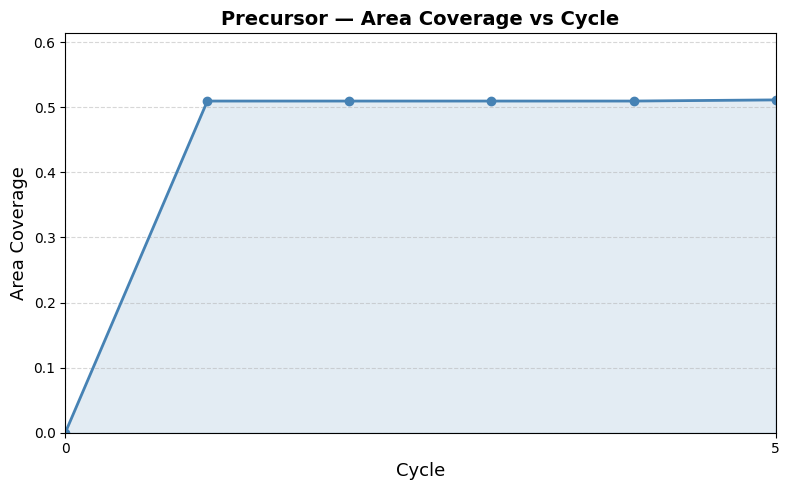

C:\Users\dangh\AppData\Local\Temp\ipykernel_13024\3359316731.py:46: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax2.set_ylim(0, area_coverage_inhibitor_per_cycle.max() * 1.2)


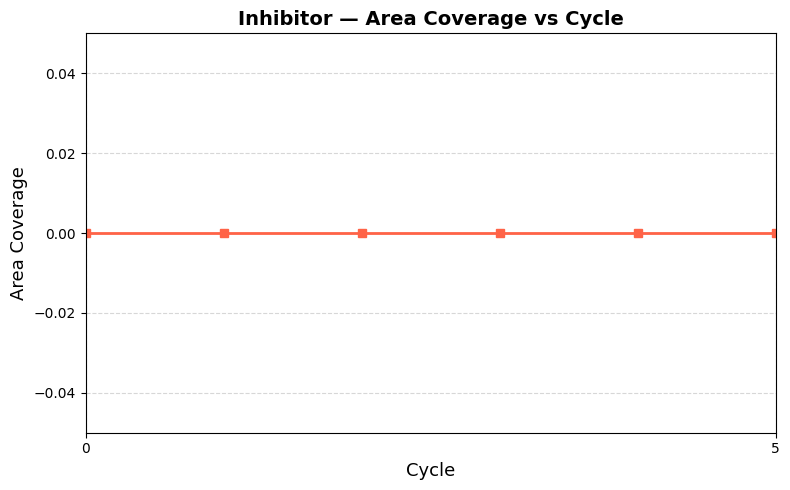

In [12]:
cycles = np.arange(0, N + 1)

# Cumulative area coverage theo từng cycle
cumulative_precursor = np.cumsum(number_ads_precursor)
cumulative_inhibitor = np.cumsum(number_ads_inhibitors)
area_coverage_precursor_per_cycle = np.concatenate([[0], (np.cumsum(number_ads_precursor) * precursor_area_nm2) / surface_area_nm2])
area_coverage_inhibitor_per_cycle = np.concatenate([[0], (np.cumsum(number_ads_inhibitors) * inhibitor_area_nm2) / surface_area_nm2])

# ── Đồ thị 1: Precursor ──────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(cycles, area_coverage_precursor_per_cycle,
         marker='o', color='steelblue', linewidth=2, markersize=6, label='Precursor')
ax1.fill_between(cycles, area_coverage_precursor_per_cycle, alpha=0.15, color='steelblue')
#for x, y in zip(cycles, area_coverage_precursor_per_cycle):
#    ax1.annotate(f'{y:.3f}', xy=(x, y), xytext=(0, 8),
#                 textcoords='offset points', ha='center', fontsize=9)
ax1.set_xlabel('Cycle', fontsize=13)
ax1.set_ylabel('Area Coverage', fontsize=13)
ax1.set_title('Precursor — Area Coverage vs Cycle', fontsize=14, fontweight='bold')
#ax1.set_xticks(cycles)
#ax1.set_xlim(0, N + 0.5)
ax1.set_xticks(np.arange(0, N + 1, 5))
ax1.set_xlim(0, N)
ax1.set_ylim(0, area_coverage_precursor_per_cycle.max() * 1.2)
#ax1.legend(fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('precursor_area_coverage_vs_cycle.png', dpi=300, bbox_inches='tight')
plt.show()

# ── Đồ thị 2: Inhibitor ──────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.plot(cycles, area_coverage_inhibitor_per_cycle,
         marker='s', color='tomato', linewidth=2, markersize=6, label='Inhibitor')
ax2.fill_between(cycles, area_coverage_inhibitor_per_cycle, alpha=0.15, color='tomato')
#for x, y in zip(cycles, area_coverage_inhibitor_per_cycle):
#    ax2.annotate(f'{y:.3f}', xy=(x, y), xytext=(0, 8),
#                 textcoords='offset points', ha='center', fontsize=9)
ax2.set_xlabel('Cycle', fontsize=13)
ax2.set_ylabel('Area Coverage', fontsize=13)
ax2.set_title('Inhibitor — Area Coverage vs Cycle', fontsize=14, fontweight='bold')
#ax2.set_xticks(cycles)
#ax2.set_xlim(0, N + 0.5)
ax2.set_xticks(np.arange(0, N + 1, 5))
ax2.set_xlim(0, N)
ax2.set_ylim(0, area_coverage_inhibitor_per_cycle.max() * 1.2)
#ax2.legend(fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('inhibitor_area_coverage_vs_cycle.png', dpi=300, bbox_inches='tight')
plt.show()

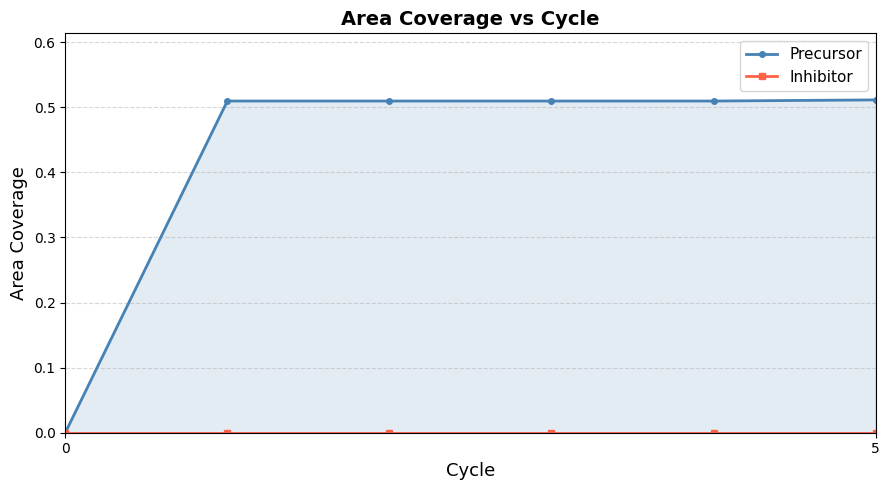

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

# Precursor
ax.plot(cycles, area_coverage_precursor_per_cycle,
        marker='o', color='steelblue', linewidth=2, markersize=4, label='Precursor')
ax.fill_between(cycles, area_coverage_precursor_per_cycle, alpha=0.15, color='steelblue')

# Inhibitor
ax.plot(cycles, area_coverage_inhibitor_per_cycle,
        marker='s', color='tomato', linewidth=2, markersize=4, label='Inhibitor')
ax.fill_between(cycles, area_coverage_inhibitor_per_cycle, alpha=0.15, color='tomato')

# Labels
ax.set_xlabel('Cycle', fontsize=13)
ax.set_ylabel('Area Coverage', fontsize=13)
ax.set_title('Area Coverage vs Cycle', fontsize=14, fontweight='bold')

#ax.set_xticks(cycles)
#ax.set_xlim(0, N + 0.5)
ax.set_xticks(np.arange(0, N + 1, 5))
ax.set_xlim(0, N)

# Quan trọng: lấy max của cả 2
ymax = max(area_coverage_precursor_per_cycle.max(),
           area_coverage_inhibitor_per_cycle.max())
ax.set_ylim(0, ymax * 1.2)

ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('combined_area_coverage.png', dpi=300, bbox_inches='tight')
plt.show()

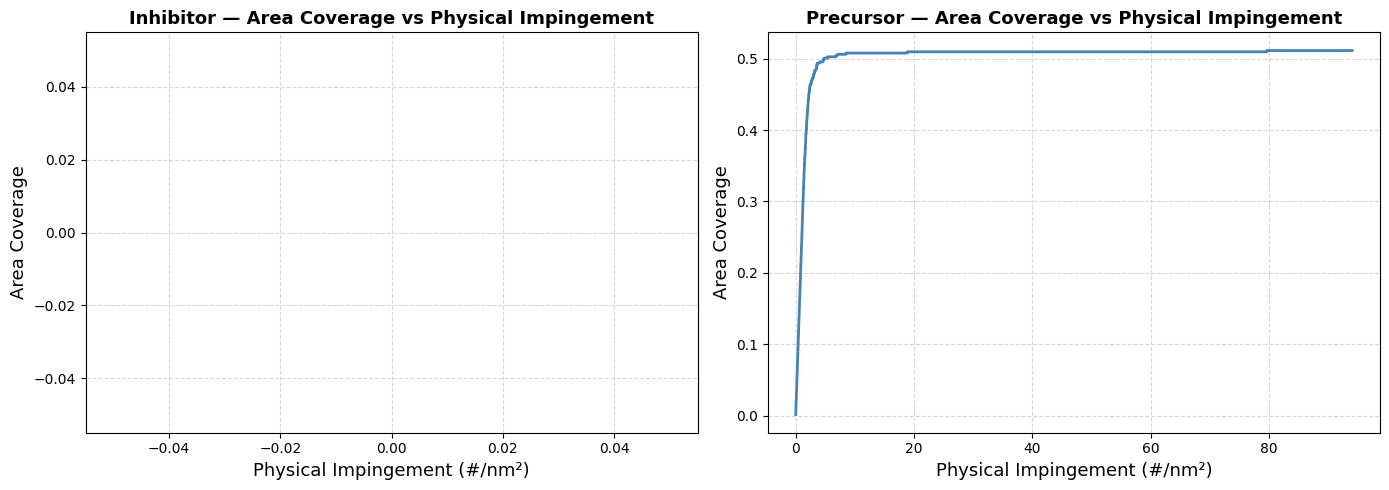

In [14]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Inhibitor
ax1.plot(all_inh_impingement_log, all_inh_coverage_log, color='tomato', linewidth=2)
ax1.set_xlabel('Physical Impingement (#/nm²)', fontsize=13)
ax1.set_ylabel('Area Coverage', fontsize=13)
ax1.set_title('Inhibitor — Area Coverage vs Physical Impingement', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# Precursor
ax2.plot(all_pre_impingement_log, all_pre_coverage_log, color='steelblue', linewidth=2)
ax2.set_xlabel('Physical Impingement (#/nm²)', fontsize=13)
ax2.set_ylabel('Area Coverage', fontsize=13)
ax2.set_title('Precursor — Area Coverage vs Physical Impingement', fontsize=13, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('coverage_vs_impingement.png', dpi=300, bbox_inches='tight')
plt.show()

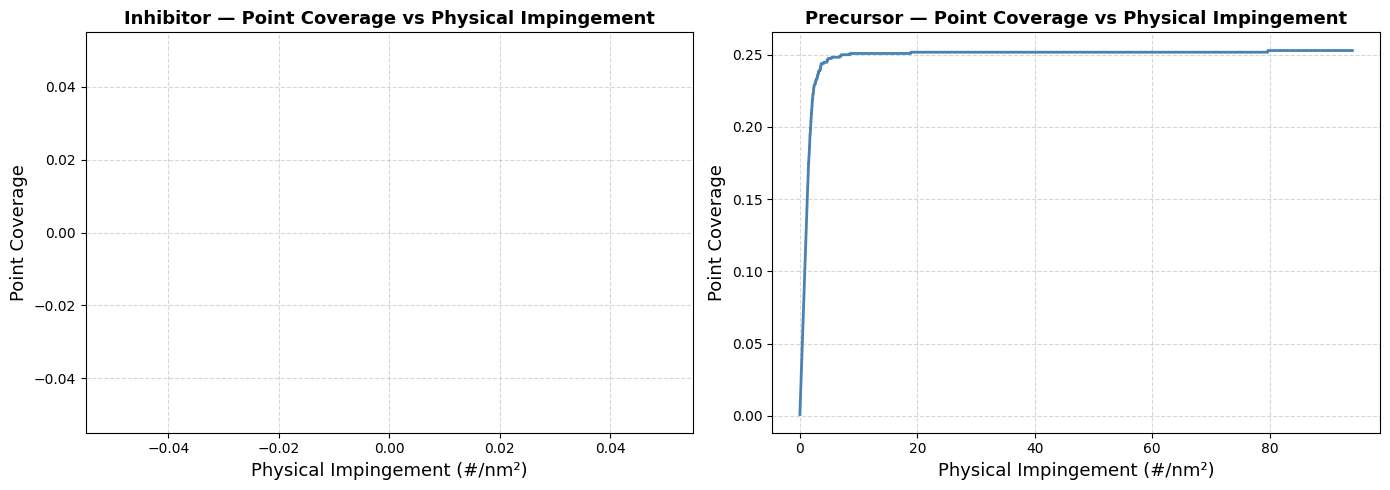

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Inhibitor
ax1.plot(all_inh_impingement_log, all_inh_point_log, color='tomato', linewidth=2)
ax1.set_xlabel('Physical Impingement (#/nm²)', fontsize=13)
ax1.set_ylabel('Point Coverage', fontsize=13)
ax1.set_title('Inhibitor — Point Coverage vs Physical Impingement', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# Precursor
ax2.plot(all_pre_impingement_log, all_pre_point_log, color='steelblue', linewidth=2)
ax2.set_xlabel('Physical Impingement (#/nm²)', fontsize=13)
ax2.set_ylabel('Point Coverage', fontsize=13)
ax2.set_title('Precursor — Point Coverage vs Physical Impingement', fontsize=13, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('point_coverage_vs_impingement.png', dpi=300, bbox_inches='tight')
plt.show()

# Demo

In [ ]:
def generate_slab_from_cif(cif_path, miller_indices=(1, 0, 0), layers=4, vacuum=10.0, repeat=(4, 4, 1)):
    structure = read(cif_path)
    slab = surface(structure, miller_indices, layers=layers, vacuum=vacuum)

    # --- Chuyển sang orthogonal cell ---
    # surface() giữ nguyên cell gốc từ CIF, nên a1/a2 có thể không vuông góc (hình bình hành).
    # Cần tìm tổ hợp tuyến tính nguyên của a1, a2 để tạo 2 vector mới vuông góc nhau.
    #
    # Ý tưởng: giữ nguyên a1 làm trục x, sau đó tìm (p, q) nguyên sao cho:
    #   new_a2 = q*a2 - p*a1  vuông góc với a1
    #
    # Điều kiện vuông góc: dot(new_a2, a1) = 0
    #   => dot(q*a2 - p*a1, a1) = 0
    #   => q*dot(a2,a1) = p*|a1|²
    #   => p/q = dot(a2,a1) / |a1|²
    #
    # Vậy chỉ cần xấp xỉ ratio = dot(a2,a1)/|a1|² bằng phân số p/q (q <= max_denom).
    # Ghi nhớ top element từ surface() TRƯỚC khi cut() tránh đảo lộn bề mặt
    z_ref = slab.get_positions()[:, 2]
    cell_z_ref = slab.get_cell()[2, 2]
    frac_z_max = z_ref.max() / cell_z_ref  # nếu gần 1.0 → slab sát đỉnh → bị đảo lộn
    
    a1, a2 = slab.cell[0], slab.cell[1]
    ratio = np.dot(a2, a1) / np.dot(a1, a1)  # = p/q cần tìm

    # Tìm p/q xấp xỉ ratio tốt nhất với mẫu số q <= 20
    best_p, best_q, best_err = 0, 1, abs(ratio)
    for q in range(1, 21):
        p = round(q * ratio)
        err = abs(q * ratio - p)
        if err < best_err:
            best_p, best_q, best_err = p, q, err
        if err < 1e-6:
            break

    # Dùng ASE cut() để cắt lại supercell với basis mới:
    #   new_a1 = best_q * old_a1          (vẫn hướng cũ, nhân best_q lần)
    #   new_a2 = best_q * old_a2 - best_p * old_a1  (vuông góc với new_a1)
    #   new_a3 = giữ nguyên               (hướng vacuum, không đổi)
    slab = cut(
        slab,
        a=( best_q,        0, 0),   # new_a1 theo fractional coords
        b=(-best_p,  best_q, 0),    # new_a2 theo fractional coords
        c=None,                      # giữ nguyên a3
        extend=1.05,                 # lấy dư 5% tránh bỏ sót atom ở biên
        tolerance=0.5
    )

    # cut() đôi khi để lại cell hơi lệch do floating point,
    # nên force cell thành hình chữ nhật hoàn toàn (chỉ scale vị trí atom theo tỉ lệ).
    lx, ly, lz = [np.linalg.norm(slab.cell[i]) for i in range(3)]
    slab.set_cell([[lx,0,0],[0,ly,0],[0,0,lz]], scale_atoms=True)

    # Xóa duplicate atoms phát sinh do extend=1.05
    dup = get_duplicate_atoms(slab, cutoff=0.1)
    if len(dup):
        del slab[dup]

    # FIX: nếu slab nằm sát đỉnh cell (frac_z_max gần 1) → bị đảo lộn → flip
    z_pos = slab.get_positions()[:, 2]
    cell_z = slab.get_cell()[2, 2]
    if z_pos.min() > cell_z - z_pos.max():  # vacuum_bot > vacuum_top
        z_mid = (z_pos.max() + z_pos.min()) / 2
        slab.positions[:, 2] = 2 * z_mid - slab.positions[:, 2]

    slab.cell[2, 2] = slab.get_positions()[:, 2].max() + vacuum
    
    # --- Repeat và PBC ---
    slab = slab.repeat(repeat)
    slab.pbc = [True, True, True]

    a1, a2 = slab.cell[0], slab.cell[1]
    surface_area_nm2 = np.linalg.norm(np.cross(a1, a2)) / 100

    z_pos = slab.get_positions()[:, 2]
    syms = np.array(slab.get_chemical_symbols())
    print(f"Top layer: {set(syms[np.abs(z_pos - z_pos.max()) < 0.1])} @ z={z_pos.max():.3f}")
    print(f"Bot layer: {set(syms[np.abs(z_pos - z_pos.min()) < 0.1])} @ z={z_pos.min():.3f}")
    print(f"Slab: Miller {miller_indices}, {len(slab)} atoms")
    print(f"Cell: {slab.cell}")
    print(f"Surface area: {surface_area_nm2:.4f} nm²")

    return slab, surface_area_nm2





Top layer: {np.str_('O')} @ z=11.615
Bot layer: {np.str_('Si')} @ z=10.000
Slab: Miller (0, 0, 1), 1152 atoms
Cell: Cell([126.61512864, 109.65191790567462, 21.61532530669194])
Surface area: 138.8359 nm²


In [7]:
# Generate slab and surface area
slab, surface_area_nm2 = generate_slab_from_cif(
    r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\CIF Files\SiO2_mp-8352_computed.cif",
    miller_indices=(0, 0, 1), layers=1, vacuum=10, repeat=(12, 12, 1)
)
surface_area_m2 = surface_area_nm2 * 1e-18

adsorption_sites = gen_adsorption_sites(slab, "ontop")

Top layer: {np.str_('O')} @ z=11.615
Bot layer: {np.str_('Si')} @ z=10.000
Slab: Miller (0, 0, 1), 1152 atoms
Cell: Cell([126.61512864, 109.65191790567462, 21.61532530669194])
Surface area: 138.8359 nm²


In [20]:
site_atoms = Atoms(
    symbols=['He'] * len(adsorption_sites),
    positions=adsorption_sites
)

# Combine với slab
combined = slab + site_atoms

# View
view(site_atoms)

<Popen: returncode: None args: ['c:\\Users\\dangh\\AppData\\Local\\Programs\...>

In [26]:
print(len(adsorption_sites), "adsorption sites generated")

2304 adsorption sites generated


In [16]:
view(slab)

<Popen: returncode: None args: ['c:\\Users\\dangh\\AppData\\Local\\Programs\...>

In [19]:
# Load molecule structures
atoms, radius = atomic_positions(r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\Structure File\TMA.sdf")
atoms_filtered = atomic_remove_indices(atoms, remove_indices=[1])

inhibitor_atoms, inhibitor_radius = atomic_positions(
    r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\Structure File\ET.sdf"
)
inhibitor_atoms_filtered = atomic_remove_indices(inhibitor_atoms, remove_indices=[8]) 

# Update radius dictionary
radius.update(inhibitor_radius)
radius['O'] = 1.52
#radius['Ru'] = 2.3
radius['Ti'] = 2.46  # Å
# Calculate molecular masses and N_hit values
#m_precursor = 72.09
#m_inhibitor = 62.14
#T = 150
#N_hit_precursor = calculate_N_hit(P, surface_area_m2, precursor_pulse_time, m_precursor, T)
#N_hit_precursor = 0
#N_hit_inhibitor = calculate_N_hit(P, surface_area_m2, inhibitor_pulse_time, m_inhibitor, T)
#N_hit_inhibitor = 0
# Generate adsorption sites (only surface sites)
#_, _, adsorption_sites = gen_adsorption_sites(slab, site_type="ontop")
#adsorption_sites = gen_adsorption_sites(slab, "bridge")
# Create working copy for site management across cycles
available_sites = adsorption_sites.copy()

# Create rotated molecule templates
selected_site = adsorption_sites[0]
rotated_adsorbate, _, _ = rotate_adsorbate_flexible(atoms_filtered, selected_site, v1_type='centroid', indices=[1, 2, 3])
rotated_inhibitor, _, _ = rotate_adsorbate_flexible(inhibitor_atoms_filtered, selected_site, v1_type='centroid', indices=[0,4,3])

C radius: 1.7
H radius: 1.2
Al radius: 1.84
Atomic symbols: ['Al', 'C', 'C', 'C', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H']
Atomic positions (Å):
[[ 1.0684  0.2044 -0.5349]
 [ 0.1205 -1.5451 -0.4216]
 [ 0.1221  1.5919  0.5433]
 [ 2.9581  0.0162  0.0727]
 [-0.3736 -1.6472  0.5646]
 [-0.6471 -1.5973 -1.2229]
 [ 0.8492 -2.3699 -0.5506]
 [ 0.5335  1.6163  1.5741]
 [ 0.264   2.5828  0.0645]
 [-0.9616  1.3566  0.5851]
 [ 3.309  -1.0185 -0.1205]
 [ 3.5924  0.73   -0.4915]
 [ 3.0309  0.2357  1.1591]]
Al: x=1.0684, y=0.2044, z=-0.5349
C: x=0.1205, y=-1.5451, z=-0.4216
C: x=0.1221, y=1.5919, z=0.5433
C: x=2.9581, y=0.0162, z=0.0727
H: x=-0.3736, y=-1.6472, z=0.5646
H: x=-0.6471, y=-1.5973, z=-1.2229
H: x=0.8492, y=-2.3699, z=-0.5506
H: x=0.5335, y=1.6163, z=1.5741
H: x=0.2640, y=2.5828, z=0.0645
H: x=-0.9616, y=1.3566, z=0.5851
H: x=3.3090, y=-1.0185, z=-0.1205
H: x=3.5924, y=0.7300, z=-0.4915
H: x=3.0309, y=0.2357, z=1.1591
Sau khi loại bỏ nguyên tử thứ [1], cấu trúc phân tử mới là:
0: Al - 

In [8]:
# Load molecule structures
atoms, radius = atomic_positions(r"C:\Users\dangh\Documents\TaiLieu\ThS Phenikaa\AS-ALD Simulation\Structure File\TMA.sdf")
#view(atoms)
atoms_filtered = atomic_remove_indices(atoms, remove_indices=[1, 4, 5, 6])
view(atoms_filtered)
selected_site = adsorption_sites[0]
rotated_adsorbate, _, _ = rotate_adsorbate_flexible(atoms_filtered, selected_site, v1_type='centroid', indices=[1, 2])

Al radius: 1.84
H radius: 1.2
C radius: 1.7
Atomic symbols: ['Al', 'C', 'C', 'C', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H']
Atomic positions (Å):
[[ 1.0684  0.2044 -0.5349]
 [ 0.1205 -1.5451 -0.4216]
 [ 0.1221  1.5919  0.5433]
 [ 2.9581  0.0162  0.0727]
 [-0.3736 -1.6472  0.5646]
 [-0.6471 -1.5973 -1.2229]
 [ 0.8492 -2.3699 -0.5506]
 [ 0.5335  1.6163  1.5741]
 [ 0.264   2.5828  0.0645]
 [-0.9616  1.3566  0.5851]
 [ 3.309  -1.0185 -0.1205]
 [ 3.5924  0.73   -0.4915]
 [ 3.0309  0.2357  1.1591]]
Al: x=1.0684, y=0.2044, z=-0.5349
C: x=0.1205, y=-1.5451, z=-0.4216
C: x=0.1221, y=1.5919, z=0.5433
C: x=2.9581, y=0.0162, z=0.0727
H: x=-0.3736, y=-1.6472, z=0.5646
H: x=-0.6471, y=-1.5973, z=-1.2229
H: x=0.8492, y=-2.3699, z=-0.5506
H: x=0.5335, y=1.6163, z=1.5741
H: x=0.2640, y=2.5828, z=0.0645
H: x=-0.9616, y=1.3566, z=0.5851
H: x=3.3090, y=-1.0185, z=-0.1205
H: x=3.5924, y=0.7300, z=-0.4915
H: x=3.0309, y=0.2357, z=1.1591
Sau khi loại bỏ nguyên tử thứ [1, 4, 5, 6], cấu trúc phân tử mới là:

In [25]:
# Calculate molecular surface areas
_, precursor_area_nm2 = molecule_surface_area(rotated_adsorbate, atom_radii=radius)
#_, inhibitor_area_nm2 = molecule_surface_area(rotated_inhibitor, atom_radii=radius)
print(f'Precursor area: {precursor_area_nm2:.4f} nm²')
#print(f'Inhibitor area: {inhibitor_area_nm2:.4f} nm²')

Diện tích bề mặt phân tử (Top view): 24.44 Å², 0.2444 nm²
Precursor area: 0.2444 nm²


In [ ]:
site_atoms = Atoms(
    symbols=['He'] * len(adsorption_sites),
    positions=adsorption_sites
)

# Combine với slab
combined = slab + site_atoms

# View
view(site_atoms)

<Popen: returncode: None args: ['c:\\Users\\dangh\\AppData\\Local\\Programs\...>

In [11]:
z_pos = slab.get_positions()[:, 2]
syms = np.array(slab.get_chemical_symbols())
print(f"Top layer: {set(syms[np.abs(z_pos - z_pos.max()) < 0.1])} @ z={z_pos.max():.3f}")
print(f"Bot layer: {set(syms[np.abs(z_pos - z_pos.min()) < 0.1])} @ z={z_pos.min():.3f}")

Top layer: {np.str_('O')} @ z=11.615
Bot layer: {np.str_('Si')} @ z=10.000
